# 04. Attributing complaints to handoff types

Two numbers answer "how much do handoffs drive complaints?":

1. **The headline:** the share of complaints handoffs cause, from LTMLE's
   "no handoffs at all" regime. The rest would happen anyway.
2. **The split:** complaints each handoff type would save if it were 10%
   rarer than today. The type effects add up to the joint effect, up to a
   small interaction that is reported.

The time-ordered split is shown at the end for comparison.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from gmethods import LTMLE, ChatSimulator, Scenario
from gmethods import interventions as iv
from gmethods.attribution import attribute, attribute_marginal, marginal_from_risks

sys.path.insert(0, str(Path("..").resolve() / "tools"))
from recovery import summarise

pd.set_option("display.width", 120)

In [2]:
import matplotlib.pyplot as plt

# Reference categorical palette, fixed order. Truth is drawn in ink.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
})

In [3]:
sim = ChatSimulator(Scenario.preset("baseline"))
data = sim.simulate(n_chats=50_000, seed=1)
model = LTMLE().fit(data.panel)
truth = pd.read_csv("../results/truth_baseline.csv", index_col="regime")

## The headline

In [4]:
table = model.estimate([iv.natural(), iv.never_any()])
risk, rd = table.risks["natural_course"], -table.rd("never_any")
low, high = (-x for x in table.ci["never_any"][::-1])
true_paf = -truth.loc["never_any", "rd"] / truth.loc["natural_course", "risk"]
print(f"complaints per 1,000 chats: {risk * 1000:.1f}")
print(f"caused by handoffs: {rd * 1000:.1f} (95% CI {low * 1000:.1f} to {high * 1000:.1f})")
print(f"share of all complaints: {rd / risk:.0%} (truth {true_paf:.0%})")

complaints per 1,000 chats: 20.3
caused by handoffs: 6.5 (95% CI 4.5 to 8.4)
share of all complaints: 32% (truth 27%)


## The marginal split

In [5]:
est = attribute_marginal(model, factor=0.9)
true = marginal_from_risks(truth["risk"].to_dict(), factor=0.9)
true_cols = true[["per_1000", "share"]].add_suffix("_true")
split = est[["per_1000", "se_per_1000", "share"]].join(true_cols)
split.round(3)

,per_1000,se_per_1000,share,per_1000_true,share_true
transfer,0.008,0.052,0.010,0.031,0.039
escalation,0.373,0.042,0.489,0.356,0.453
requeue,0.336,0.036,0.440,0.358,0.456
shift_change,0.046,0.084,0.060,0.040,0.051
all types together,0.725,0.115,NaN,0.754,NaN
interaction,-0.037,NaN,NaN,-0.032,NaN


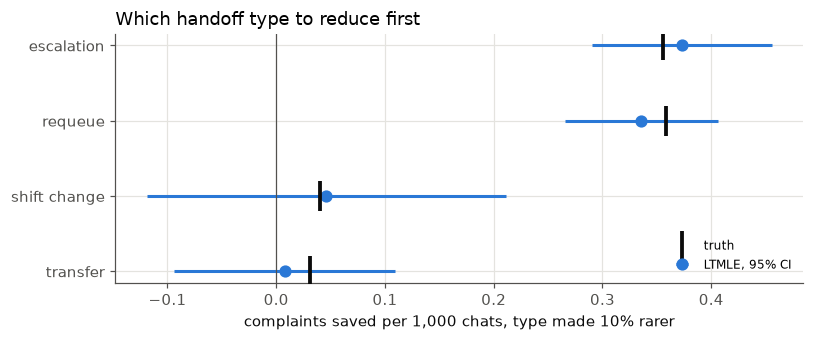

In [6]:
types = ["escalation", "requeue", "shift_change", "transfer"]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(types))
ax.errorbar(est.loc[types, "per_1000"], y, xerr=1.96 * est.loc[types, "se_per_1000"],
            fmt="o", color=SERIES[0], ms=7, lw=2, capsize=0, label="LTMLE, 95% CI")
ax.scatter(true.loc[types, "per_1000"], y, marker="|", s=400, color=INK, lw=2.5,
           label="truth", zorder=4)
ax.set_yticks(y, [t.replace("_", " ") for t in types])
ax.invert_yaxis()
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("complaints saved per 1,000 chats, type made 10% rarer")
ax.set_title("Which handoff type to reduce first", loc="left")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

## Recovery across datasets

LTMLE's marginal split across 20 datasets of 50,000 chats. Regenerate with
`uv run python tools/recovery.py --regimes marginal --estimators ltmle --tag marginal`.

In [7]:
files = sorted(Path("../results").glob("recovery_baseline_n50000_marginal_*.csv"))
rec = summarise(files, Path("../results/truth_baseline.csv")).xs(50_000, level="n_chats")
rec = rec.xs("ltmle", level="estimator")
out = rec[["rd_true", "rd_mean", "sd", "rmse"]] * -1000
out[["sd", "rmse"]] *= -1
out["coverage"] = rec["coverage"]
out["reps"] = rec["reps"]
out.round(3)

,rd_true,rd_mean,sd,rmse,coverage,reps
regime,,,,,,
scale_any_0.9,0.754,0.744,0.092,0.090,1.0,20
scale_escalation_0.9,0.356,0.364,0.033,0.033,1.0,20
scale_requeue_0.9,0.358,0.340,0.043,0.045,0.9,20
scale_shift_change_0.9,0.040,0.044,0.068,0.067,1.0,20
scale_transfer_0.9,0.031,0.029,0.047,0.046,1.0,20


## For comparison: the time-ordered split

Credit goes turn by turn, each turn valued with every earlier handoff
already removed. It splits the whole attributable risk, but later types are
valued in a world where chats run longer than they do today, and LTMLE
estimates it far less precisely. Truth from one million simulated chats:

In [8]:
risks = pd.read_csv("../results/attribution_truth_baseline.csv", index_col="regime")
time_ordered = attribute(risks["risk"].to_dict(), label="truth").summary()
time_ordered[["per_1000", "share_of_handoff_complaints"]].round(3)

,per_1000,share_of_handoff_complaints
transfer,0.388,0.068
escalation,1.722,0.302
requeue,1.621,0.285
shift_change,1.962,0.345
all handoffs,5.693,1.000
not caused by handoffs,15.384,NaN
